intro_to_Language_modeling part3  Continuation..
------

[video link](https://youtu.be/P6sfmUTpUmc?list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ&t=4715)

**Goal**
1. Pytorch-ifying the previous code(i.e make classes similar to nn.Module in PyTorch)
2. train a deeper network (6 layers)
3. check activation satistics (forward and back pass)

Initial Setup
------

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [2]:
# download the training data
!curl https://raw.githubusercontent.com/karpathy/makemore/refs/heads/master/names.txt -o names.txt

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  222k  100  222k    0     0   586k      0 --:--:-- --:--:-- --:--:--  587k


In [3]:
words = open('names.txt', 'r').read().splitlines()

In [4]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [5]:
# build the dataset for training,dev and test split
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):
  X, Y = [], []

  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80% training split
Xdev, Ydev = build_dataset(words[n1:n2])   # 10% dev split
Xte,  Yte  = build_dataset(words[n2:])     # 10% test split

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


Pytorch-ifying the previous code and visualize tahn and parameters behaviour
------
Here we create custom classes for layers, BatchNorm1d etc

In [6]:
# The classes create here are the same API as nn.Module in PyTorch

# to create a linear layer
class Linear: # similar to https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html

  def __init__(self, fan_in, fan_out, bias=True):
    # similar to Kaiming init that we did to fix saturated tanh
    self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in**0.5 # we could omit divison by 'fan_in**0.5', but keeping the Kaiming initialization (/ fan_in**0.5) is still a good practice and generally helps the training process.
    self.bias = torch.zeros(fan_out) if bias else None # biases initialized to zero

  def __call__(self, x): # similar to x@W+b
    self.out = x @ self.weight
    if self.bias is not None:
      self.out += self.bias
    return self.out

  def parameters(self): # return parameters of this layer
    return [self.weight] + ([] if self.bias is None else [self.bias])


# for Batch Normalization
class BatchNorm1d: #similar to https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html

  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.momentum = momentum
    self.training = True # a flag to indicate if its for training phase
    # parameters (trained with backprop)
    self.gamma = torch.ones(dim) #similar to previous bngain
    self.beta = torch.zeros(dim) # similar to previous bnbias
    # buffers (trained with a running 'momentum update')
    self.running_mean = torch.zeros(dim) # similar to previous bnmean_running
    self.running_var = torch.ones(dim) # similar to previous bnstd_running

  def __call__(self, x):
    # calculate the forward pass
    if self.training:
      xmean = x.mean(0, keepdim=True) # batch mean
      xvar = x.var(0, keepdim=True) # batch variance
    else:
      xmean = self.running_mean
      xvar = self.running_var
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps) # normalize to unit variance
    self.out = self.gamma * xhat + self.beta
    # update the buffers (similar how we updated bnmean_running and bnstd_running)
    if self.training:
      with torch.no_grad():
        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
        self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
    return self.out

  def parameters(self):
    return [self.gamma, self.beta]

# to claculate tanh
class Tanh:
  def __call__(self, x):
    self.out = torch.tanh(x)
    return self.out
  def parameters(self):
    return []

############### init the network ###################


# set network variables
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 100 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(2147483647) # for reproducibility

# init embedding
C = torch.randn((vocab_size, n_embd),            generator=g)

# init 11 layer(5 linear layers, 5 Tanh layers, 1 softmax/output layer)
layers = [
  Linear(n_embd * block_size, n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden), Tanh(),
  Linear(           n_hidden, vocab_size),
]

with torch.no_grad():
  layers[-1].weight *= 0.1 # making last layer a bit less confident
  # all other layers: apply gain
  for layer in layers[:-1]:
    if isinstance(layer, Linear):
      layer.weight *= 5/3 # boosting the weight a bit

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print("total parameters",sum(p.nelement() for p in parameters))
for p in parameters:
  p.requires_grad = True


total parameters 46497


In [8]:
# Training the neuralnel
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  x = emb.view(emb.shape[0], -1) # concatenate the vectors
  ### dynamically creating layers
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, Yb) # loss function

  # backward pass
  for layer in layers:
    layer.out.retain_grad() # AFTER_DEBUG: would take out retain_graph
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad # stochastic gradient descent

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

  break # breaking after one iteration

      0/ 200000: 3.2944


layer 1 (      Tanh): mean -0.02, std 0.76, saturated: 21.03%
layer 3 (      Tanh): mean +0.00, std 0.68, saturated: 8.38%
layer 5 (      Tanh): mean -0.00, std 0.67, saturated: 7.37%
layer 7 (      Tanh): mean -0.03, std 0.66, saturated: 5.66%
layer 9 (      Tanh): mean -0.03, std 0.66, saturated: 6.66%


Text(0.5, 1.0, 'activation distribution')

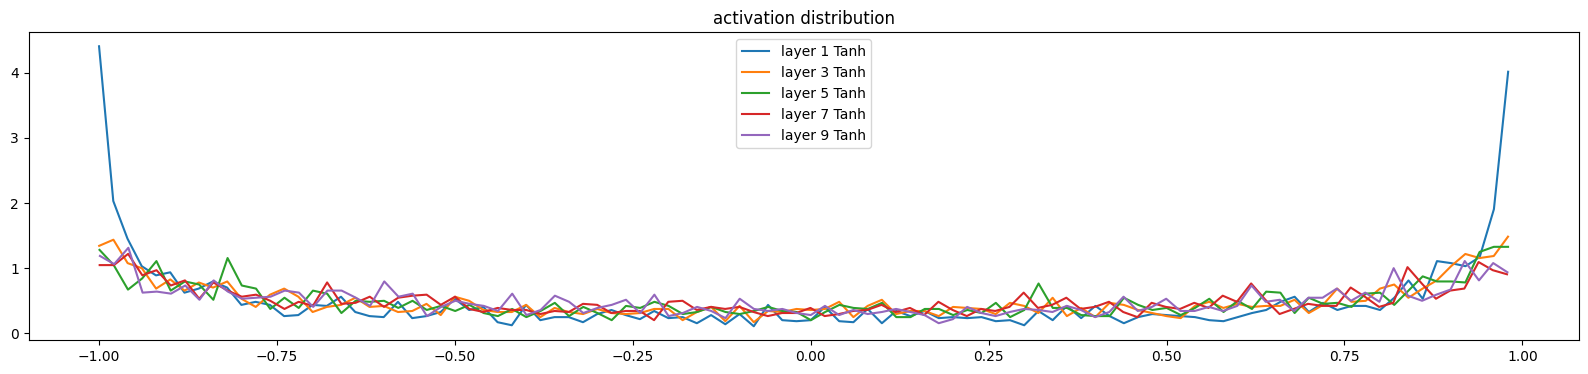

In [9]:
# Visualizes the distribution of activations for each Tanh layer
# This visualization helps understand how the outputs of activation functions are distributed,
# which can be useful for debugging and improving your network's training.
# Ideally, you want the activations to be centered around zero and have a reasonable spread to avoid issues like vanishing gradients

plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh): # taking only tanh layer
    t = layer.out
    saturation = (t.abs() > 0.97).float().mean()*100 # percentage of items that are greater than 0.97 in tanh outputs
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), saturation))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} {layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution')

layer 1 (      Tanh): mean -0.000018, std 4.739166e-04
layer 3 (      Tanh): mean -0.000013, std 4.471041e-04
layer 5 (      Tanh): mean +0.000020, std 4.165248e-04
layer 7 (      Tanh): mean +0.000008, std 3.662141e-04
layer 9 (      Tanh): mean +0.000010, std 3.220131e-04


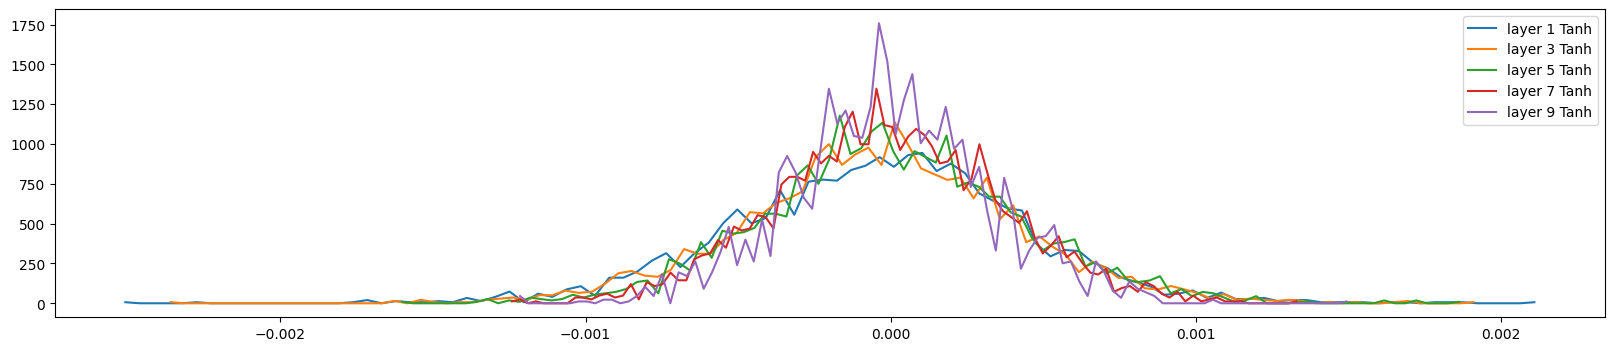

In [10]:
# Visualizes the distribution of the gradients for the outputs of each Tanh layer
# This visualization helps understand how the gradients are flowing back through your network.
# Ideally, you want to see a healthy distribution of gradients, not ones that are extremely small (vanishing gradients) or extremely large (exploding gradients), as these can hinder effective training.

plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} {layer.__class__.__name__}')
plt.legend(legends);

weight   (27, 10) | mean -0.000031 | std 1.365078e-03 | grad:data ratio 1.364090e-03
weight  (30, 100) | mean -0.000049 | std 1.207430e-03 | grad:data ratio 3.871660e-03
weight (100, 100) | mean +0.000016 | std 1.096730e-03 | grad:data ratio 6.601988e-03
weight (100, 100) | mean -0.000010 | std 9.893572e-04 | grad:data ratio 5.893091e-03
weight (100, 100) | mean -0.000011 | std 8.623432e-04 | grad:data ratio 5.158124e-03
weight (100, 100) | mean -0.000004 | std 7.388576e-04 | grad:data ratio 4.415211e-03
weight  (100, 27) | mean -0.000000 | std 2.364824e-02 | grad:data ratio 2.328203e+00


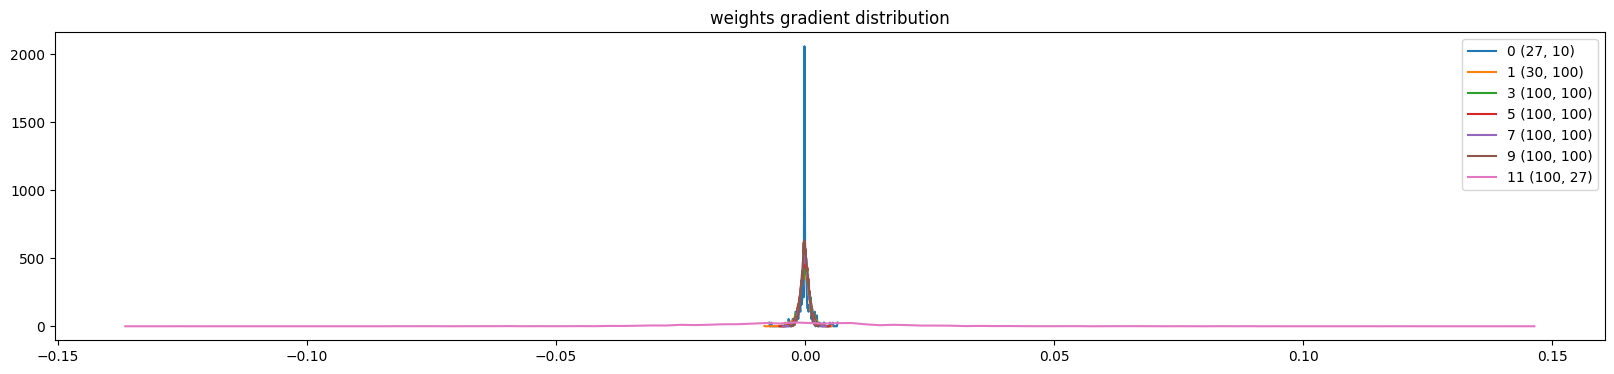

In [19]:
# Visualizes the distribution of the gradients for the weight parameters of each layer
# This visualization helps you understand the magnitude and distribution of the gradients that are used to update the weights during training
# It can be useful for identifying potential issues like vanishing or exploding gradients in specific layers
# The grad:data ratio is particularly interesting as it shows how large the updates are relative to the parameters themselves. A very small ratio might indicate slow learning, while a very large ratio could suggest unstable training
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2: # taking only the weight parameters
    grad_data_ratio = t.std() / p.std() #checking to ensure that the values of param.grad is smaller than param.value
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), grad_data_ratio ))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

#### ploting visualization again for 1000 iterations

In [11]:
# Training the neuralnel
max_steps = 200000
batch_size = 32
lossi = []
ud = [] # to hold update to data ratio

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  x = emb.view(emb.shape[0], -1) # concatenate the vectors
  ### dynamically creating layers
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, Yb) # loss function

  # backward pass
  for layer in layers:
    layer.out.retain_grad() # AFTER_DEBUG: would take out retain_graph
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad # stochastic gradient descent

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())
  ## calculating update to data the ratio
  with torch.no_grad():
    # here (lr*p.grad).std() is the update value added to param
    # here p.data.std() is the actual param data/value
    ud.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters])

  if i >= 1000:
    break

      0/ 200000: 3.2169


layer 1 (      Tanh): mean -0.05, std 0.76, saturated: 20.47%
layer 3 (      Tanh): mean -0.01, std 0.72, saturated: 11.75%
layer 5 (      Tanh): mean +0.02, std 0.74, saturated: 14.78%
layer 7 (      Tanh): mean -0.06, std 0.73, saturated: 13.59%
layer 9 (      Tanh): mean -0.02, std 0.71, saturated: 11.62%


Text(0.5, 1.0, 'activation distribution')

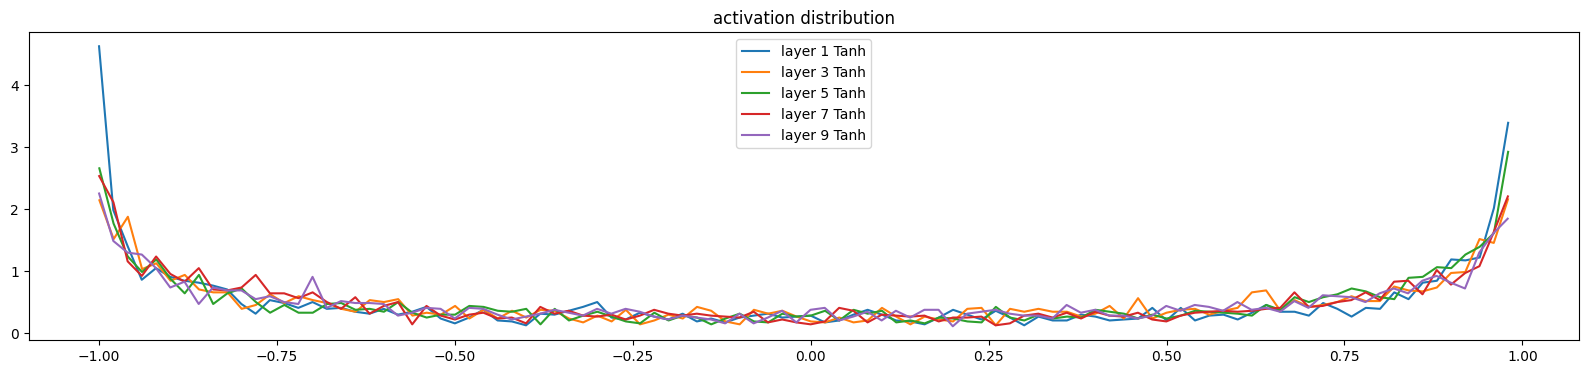

In [13]:
# Visualizes the distribution of activations for each Tanh layer
# This visualization helps understand how the outputs of activation functions are distributed,
# which can be useful for debugging and improving your network's training.
# Ideally, you want the activations to be centered around zero and have a reasonable spread to avoid issues like vanishing gradients

plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh): # taking only tanh layer
    t = layer.out
    saturation = (t.abs() > 0.97).float().mean()*100 # percentage of items that are greater than 0.97 in tanh outputs
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), saturation))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} {layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution')

layer 1 (      Tanh): mean -0.000035, std 2.810548e-03
layer 3 (      Tanh): mean -0.000005, std 2.728146e-03
layer 5 (      Tanh): mean -0.000004, std 2.734530e-03
layer 7 (      Tanh): mean +0.000022, std 2.572811e-03
layer 9 (      Tanh): mean +0.000010, std 2.229641e-03


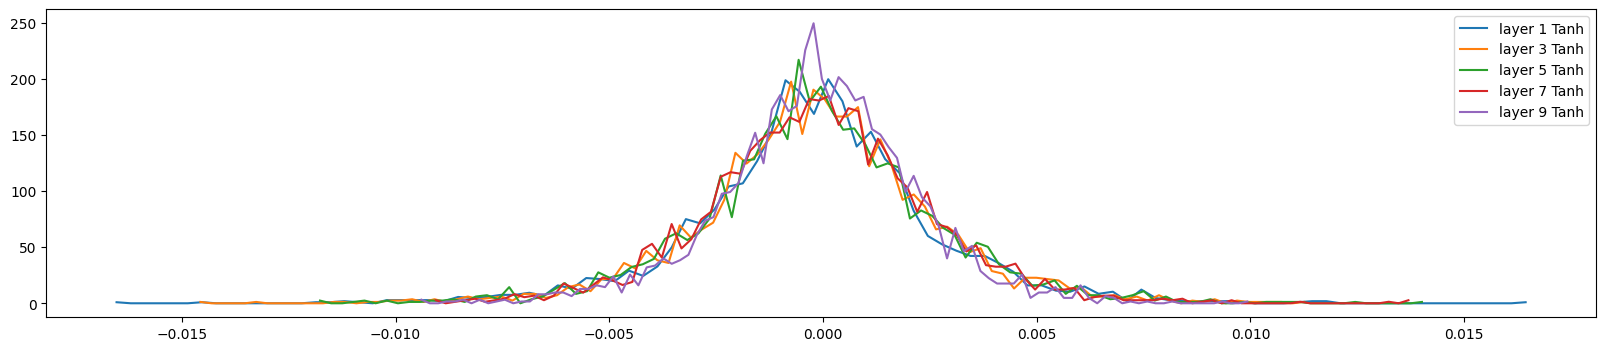

In [14]:
# Visualizes the distribution of the gradients for the outputs of each Tanh layer
# This visualization helps understand how the gradients are flowing back through your network.
# Ideally, you want to see a healthy distribution of gradients, not ones that are extremely small (vanishing gradients) or extremely large (exploding gradients), as these can hinder effective training.

plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} {layer.__class__.__name__}')
plt.legend(legends);

weight   (27, 10) | mean +0.000543 | std 1.210879e-02 | grad:data ratio 1.210873e-02
weight  (30, 100) | mean +0.000091 | std 8.572477e-03 | grad:data ratio 2.741174e-02
weight (100, 100) | mean -0.000079 | std 6.680251e-03 | grad:data ratio 3.974533e-02
weight (100, 100) | mean -0.000033 | std 6.521376e-03 | grad:data ratio 3.846636e-02
weight (100, 100) | mean +0.000037 | std 6.064260e-03 | grad:data ratio 3.592852e-02
weight (100, 100) | mean -0.000092 | std 5.176418e-03 | grad:data ratio 3.075116e-02
weight  (100, 27) | mean -0.000000 | std 2.309357e-02 | grad:data ratio 3.261763e-01


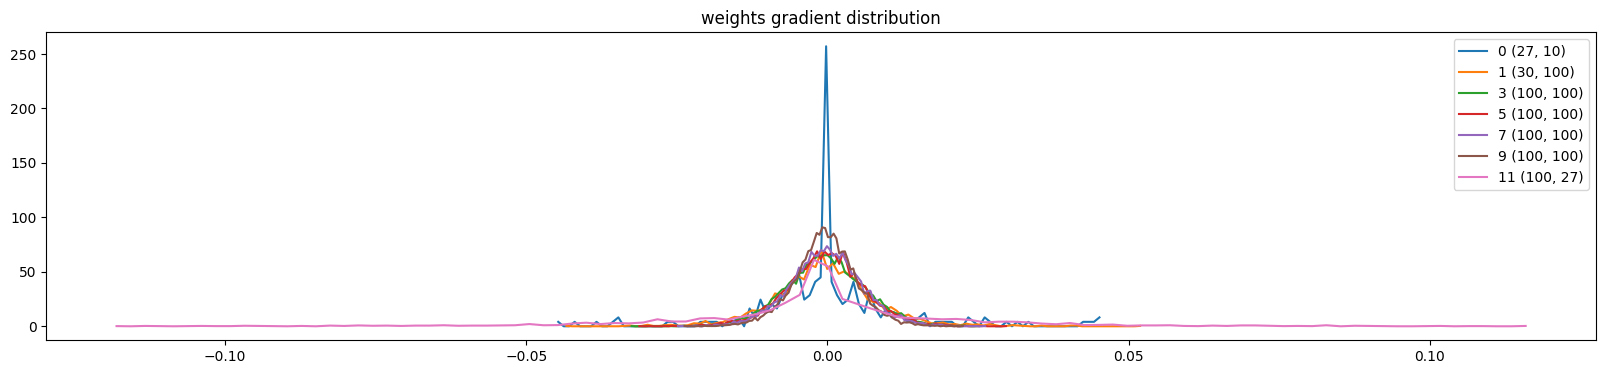

In [15]:
# Visualizes the distribution of the gradients for the weight parameters of each layer
# This visualization helps you understand the magnitude and distribution of the gradients that are used to update the weights during training
# It can be useful for identifying potential issues like vanishing or exploding gradients in specific layers
# The grad:data ratio is particularly interesting as it shows how large the updates are relative to the parameters themselves. A very small ratio might indicate slow learning, while a very large ratio could suggest unstable training
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2: # taking only the weight parameters
    grad_data_ratio = t.std() / p.std() #checking to ensure that the values of param.grad is smaller than param.value
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), grad_data_ratio ))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

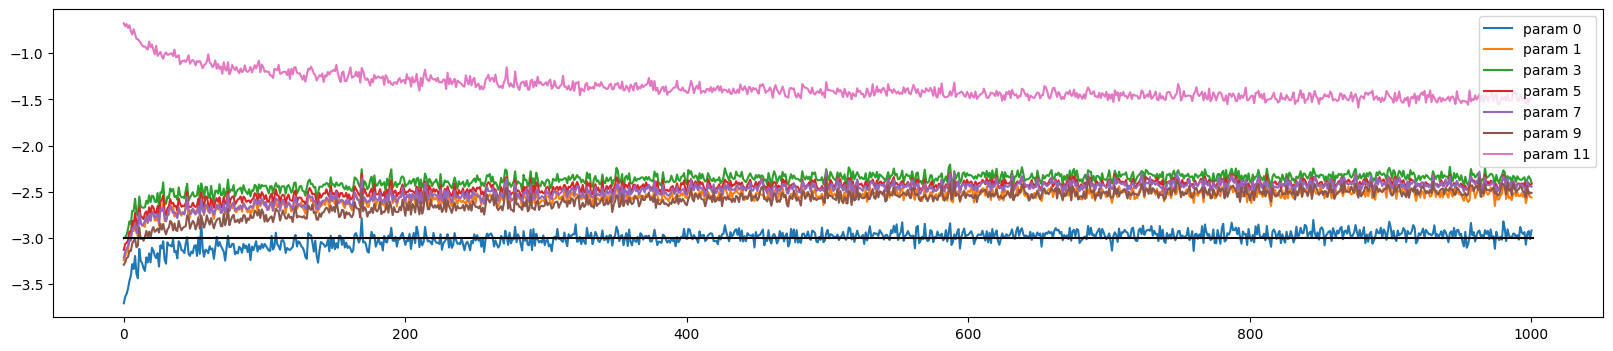

In [16]:
# Visualizes the "update-to-data" ratio for the weight parameters over the training steps-  it shows how large the updates applied to your model's weights are relative to the current values of those weights during training
# Monitoring this plot helps you diagnose potential issues with your training process, particularly related to the learning rate and gradient flow, and informs decisions about adjusting hyperparameters to achieve more stable and efficient training
# it has a horizonatl reference line at y=-3 representing a desired update-to-data ratio.  It suggests that, ideally, the magnitude of the updates to your parameters in each step should be around 0.1% of the current value of the parameters
# If the ratio is consistently below 0.1%(y=-3), it indicates that the updates are very small relative to the parameter values, which might suggest that the learning rate is too low and the training is progressing slowly
# # If the ratio is consistently above 0.1%(y=-3), it indicates that the updates are relatively large. This could indicate that the learning rate is too high, potentially leading to unstable training or oscillations

plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2: # taking only the weight parameters
    plt.plot([ud[j][i] for j in range(len(ud))])
    legends.append('param %d' % i)
# plots a horizontal visual reference line at y = -3 . It suggests that, ideally, the magnitude of the updates to your parameters in each step should be around 0.1% of the current value of the parameters
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);

Why are we calculating standard deivations for plotting most of the visulaization ?

Standard deviation is used because it's a good way to understand the distribution and spread of important values (activations, gradients, parameter updates) within the neural network, helping us diagnose potential training issues. In general Standard deviation is a statistical measure that quantifies the amount of variation or dispersion of a set of data values. In simpler terms, it tells you how spread out the numbers are from their average

1. For activations (like the Tanh outputs): The standard deviation tells us how spread out the outputs of the activation function are. A very low standard deviation might mean most activations are clustered near the mean, possibly indicating saturation or that the network isn't utilizing the full range of the activation function. A healthy spread (a reasonable standard deviation) is generally desired.

2. For gradients: The standard deviation of the gradients tells us how much the gradients vary. This is important for understanding the flow of gradients during backpropagation. Very small standard deviations across layers can indicate vanishing gradients, while very large ones can suggest exploding gradients.

3. For the update-to-data ratio: Using the standard deviation of the updates and the standard deviation of the parameters helps to get a sense of the typical magnitude of the updates relative to the typical magnitude of the parameters, providing a more robust measure than just looking at the means.

Add batch-normalization layer to the above model and visualize
---------

In [40]:
# Init the network

# set network variables
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 100 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(2147483647) # for reproducibility

# init embedding
C = torch.randn((vocab_size, n_embd),            generator=g)

# init 17 layer(5 linear layers, 6 BatchNorm1d, 5 Tanh layers, 1 softmax/output layer)
layers = [
  Linear(n_embd * block_size, n_hidden), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, vocab_size), BatchNorm1d(vocab_size), # add BatchNorm1d to output layer as well
]

with torch.no_grad():
  layers[-1].gamma *= 0.1 # making last layer(here its BatchNorm1d) a bit less confident
  # all other layers: apply gain
  for layer in layers[:-1]:
    if isinstance(layer, Linear):
      layer.weight *= 1.0 #simply multiping by 1, so no change in weights . with Batch Normalization, you don't need to rely on carefully tuned initial gains on the Linear layer weights to prevent activation saturation

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print("total parameters",sum(p.nelement() for p in parameters))
for p in parameters:
  p.requires_grad = True

total parameters 47551


In [41]:
# Training the neuralnel
max_steps = 200000
batch_size = 32
lossi = []
ud = [] # to hold update to data ratio

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  x = emb.view(emb.shape[0], -1) # concatenate the vectors
  ### dynamically creating layers
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, Yb) # loss function

  # backward pass
  for layer in layers:
    layer.out.retain_grad() # AFTER_DEBUG: would take out retain_graph
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad # stochastic gradient descent

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())
  ## calculating update to data the ratio
  with torch.no_grad():
    # here (lr*p.grad).std() is the update value added to param
    # here p.data.std() is the actual param data/value
    ud.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters])

  if i >= 1000:
    break

      0/ 200000: 3.2870


layer 2 (      Tanh): mean -0.00, std 0.63, saturated: 2.78%
layer 5 (      Tanh): mean +0.00, std 0.64, saturated: 2.56%
layer 8 (      Tanh): mean -0.00, std 0.65, saturated: 2.25%
layer 11 (      Tanh): mean +0.00, std 0.65, saturated: 1.69%
layer 14 (      Tanh): mean +0.00, std 0.65, saturated: 1.88%


Text(0.5, 1.0, 'activation distribution')

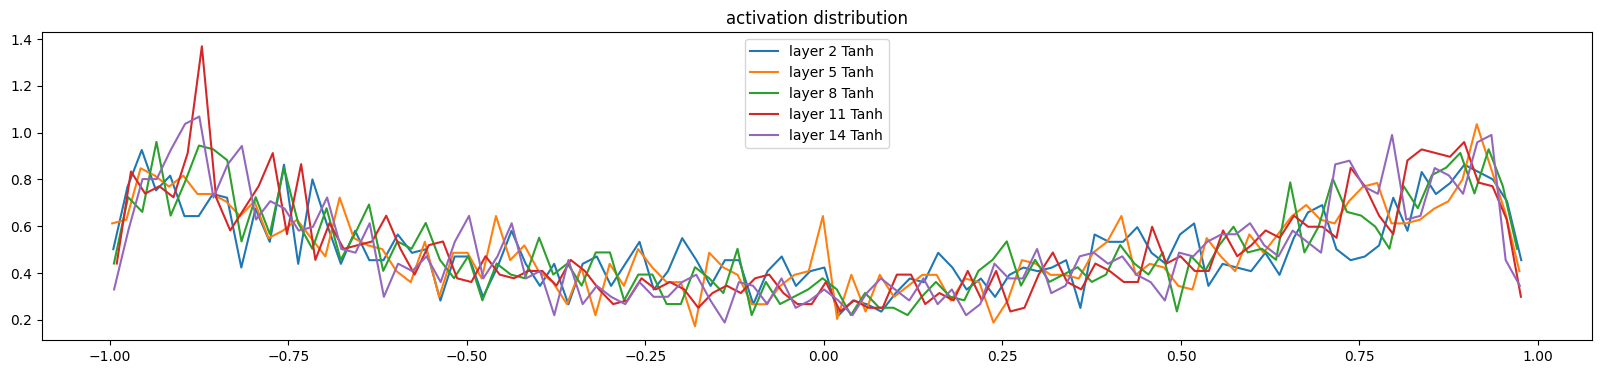

In [29]:
# Visualizes the distribution of activations for each Tanh layer
# This visualization helps understand how the outputs of activation functions are distributed,
# which can be useful for debugging and improving your network's training.
# Ideally, you want the activations to be centered around zero and have a reasonable spread to avoid issues like vanishing gradients

plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh): # taking only tanh layer
    t = layer.out
    saturation = (t.abs() > 0.97).float().mean()*100 # percentage of items that are greater than 0.97 in tanh outputs
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), saturation))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} {layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution')

layer 2 (      Tanh): mean +0.000000, std 2.640701e-03
layer 5 (      Tanh): mean +0.000000, std 2.245584e-03
layer 8 (      Tanh): mean +0.000000, std 2.045741e-03
layer 11 (      Tanh): mean -0.000000, std 1.983132e-03
layer 14 (      Tanh): mean -0.000000, std 1.952381e-03


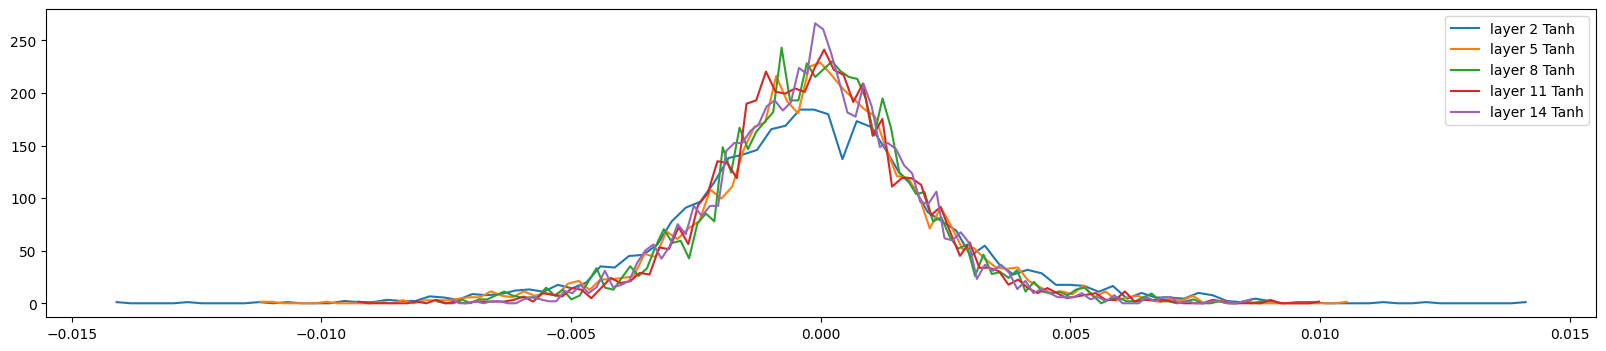

In [30]:
# Visualizes the distribution of the gradients for the outputs of each Tanh layer
# This visualization helps understand how the gradients are flowing back through your network.
# Ideally, you want to see a healthy distribution of gradients, not ones that are extremely small (vanishing gradients) or extremely large (exploding gradients), as these can hinder effective training.

plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} {layer.__class__.__name__}')
plt.legend(legends);

weight   (27, 10) | mean -0.000000 | std 8.020527e-03 | grad:data ratio 8.012623e-03
weight  (30, 100) | mean +0.000246 | std 9.241064e-03 | grad:data ratio 4.881084e-02
weight (100, 100) | mean +0.000113 | std 7.132873e-03 | grad:data ratio 6.964613e-02
weight (100, 100) | mean -0.000086 | std 6.234302e-03 | grad:data ratio 6.073738e-02
weight (100, 100) | mean +0.000052 | std 5.742181e-03 | grad:data ratio 5.631477e-02
weight (100, 100) | mean +0.000032 | std 5.672201e-03 | grad:data ratio 5.570121e-02
weight  (100, 27) | mean -0.000082 | std 1.209415e-02 | grad:data ratio 1.160105e-01


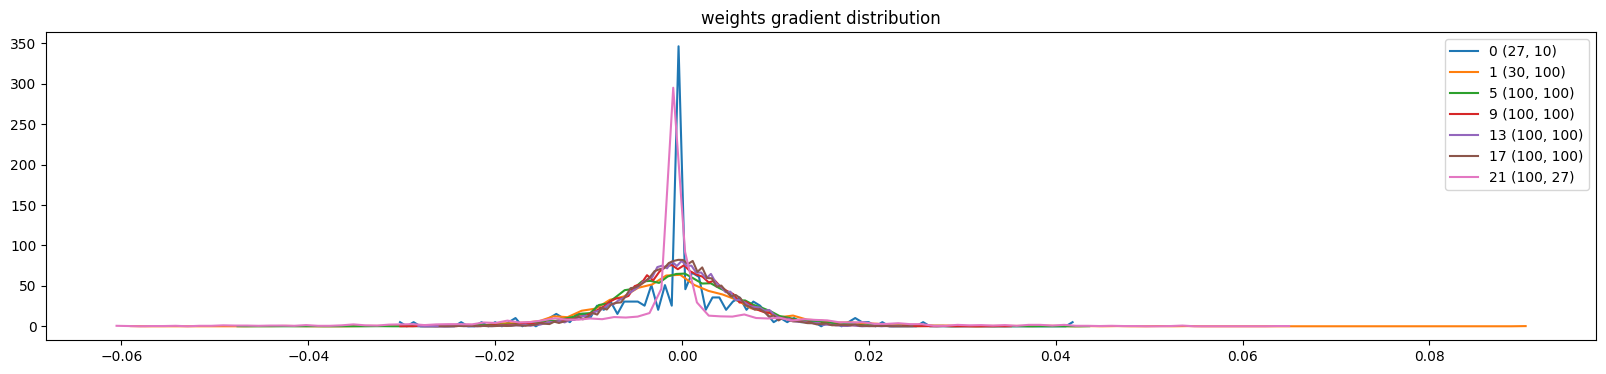

In [31]:
# Visualizes the distribution of the gradients for the weight parameters of each layer
# This visualization helps you understand the magnitude and distribution of the gradients that are used to update the weights during training
# It can be useful for identifying potential issues like vanishing or exploding gradients in specific layers
# The grad:data ratio is particularly interesting as it shows how large the updates are relative to the parameters themselves. A very small ratio might indicate slow learning, while a very large ratio could suggest unstable training
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2: # taking only the weight parameters
    grad_data_ratio = t.std() / p.std() #checking to ensure that the values of param.grad is smaller than param.value
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), grad_data_ratio ))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

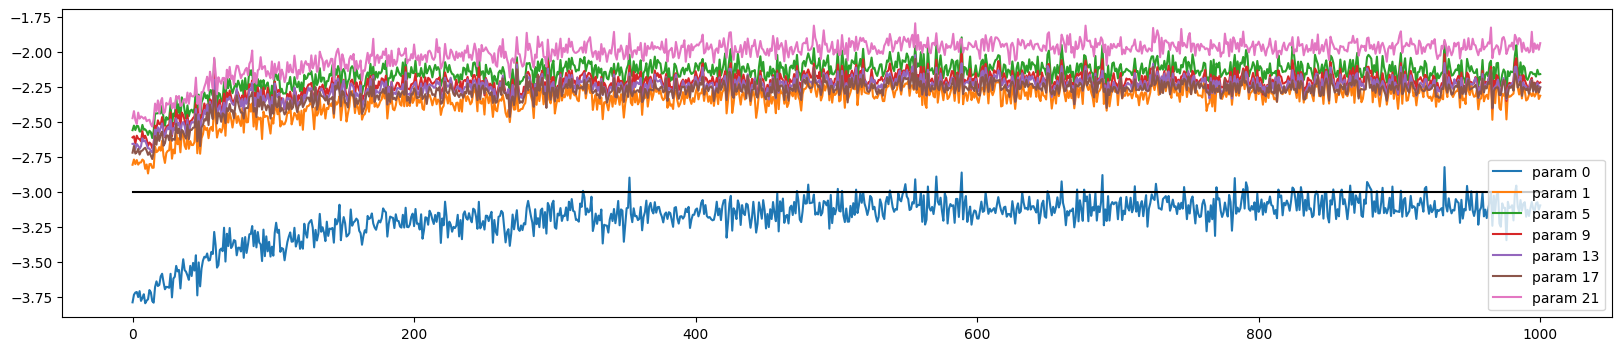

In [42]:
# Visualizes the "update-to-data" ratio for the weight parameters over the training steps-  it shows how large the updates applied to your model's weights are relative to the current values of those weights during training
# Monitoring this plot helps you diagnose potential issues with your training process, particularly related to the learning rate and gradient flow, and informs decisions about adjusting hyperparameters to achieve more stable and efficient training
# it has a horizonatl reference line at y=-3 representing a desired update-to-data ratio.  It suggests that, ideally, the magnitude of the updates to your parameters in each step should be around 0.1% of the current value of the parameters
# If the ratio is consistently below 0.1%(y=-3), it indicates that the updates are very small relative to the parameter values, which might suggest that the learning rate is too low and the training is progressing slowly
# # If the ratio is consistently above 0.1%(y=-3), it indicates that the updates are relatively large. This could indicate that the learning rate is too high, potentially leading to unstable training or oscillations

plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2: # taking only the weight parameters
    plt.plot([ud[j][i] for j in range(len(ud))])
    legends.append('param %d' % i)
# plots a horizontal visual reference line at y = -3 . It suggests that, ideally, the magnitude of the updates to your parameters in each step should be around 0.1% of the current value of the parameters
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);